In [23]:
import sys
sys.path.append("..")

from src.data_cleaning import load_data

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy

import torch
from torch import nn 
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import copy

import matplotlib.pyplot as plt

In [24]:
RANDOM_STATE = 40

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

- MLP

In [25]:
BATCH_SIZE = 16
DROPOUT = 0.3
LEARNING_RATE = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
EPOCHS = 1500


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [26]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [27]:
class MLP(nn.Module) :
    
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features, 16, device=device)
        self.layer2 = nn.Linear(16, 16, device=device)
        self.layer3 = nn.Linear(16, out_features, device=device)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=DROPOUT)

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.dropout(x)
        x = self.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.layer3(x)
        return x

In [28]:
mlp_model = MLP()
optimizer = torch.optim.SGD(params=mlp_model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

def accuracy(yt_pred, yt_true):
    return (yt_pred == yt_true).float().mean()

In [29]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS+1):

    mlp_model.train()
    mean_train_loss = 0
    mean_train_acc = 0
    mean_test_loss = 0
    mean_test_acc = 0
    
    for Xt_batch, yt_batch in train_loader :

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += train_loss.item() * Xt_batch.shape[0]/Xt_train.shape[0]

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        train_acc = accuracy(yt_pred_class, yt_batch)
        mean_train_acc += train_acc.item() * Xt_batch.shape[0]/Xt_train.shape[0]


        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()


    mlp_model.eval()

    with torch.no_grad() :
        
        yt_pred = mlp_model(Xt_val)

        val_loss = criterion(yt_pred, yt_val).item()

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        val_acc = accuracy(yt_pred_class, yt_val).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_accuracy = val_acc
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    
    if epoch%100 == 0:

        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(mean_train_acc)
        val_accuracies.append(val_acc)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f} | Train accuracy: {mean_train_acc:.2%}")
        print(f"Val loss: {val_loss:.4f} | Val accuracy: {val_acc:.2%}")
        print("")


mlp_model.load_state_dict(best_weights)
print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_val_accuracy:.2%}")

Epoch: 100
Train loss: 0.6751 | Train accuracy: 63.29%
Val loss: 0.6687 | Val accuracy: 73.33%

Epoch: 200
Train loss: 0.6430 | Train accuracy: 67.63%
Val loss: 0.6346 | Val accuracy: 77.78%

Epoch: 300
Train loss: 0.6059 | Train accuracy: 70.53%
Val loss: 0.5825 | Val accuracy: 84.44%

Epoch: 400
Train loss: 0.5673 | Train accuracy: 71.01%
Val loss: 0.5130 | Val accuracy: 86.67%

Epoch: 500
Train loss: 0.5092 | Train accuracy: 81.64%
Val loss: 0.4491 | Val accuracy: 84.44%

Epoch: 600
Train loss: 0.4887 | Train accuracy: 80.68%
Val loss: 0.4079 | Val accuracy: 84.44%

Epoch: 700
Train loss: 0.4514 | Train accuracy: 82.13%
Val loss: 0.3857 | Val accuracy: 82.22%

Epoch: 800
Train loss: 0.4387 | Train accuracy: 80.19%
Val loss: 0.3749 | Val accuracy: 82.22%

Epoch: 900
Train loss: 0.4265 | Train accuracy: 81.16%
Val loss: 0.3676 | Val accuracy: 82.22%

Epoch: 1000
Train loss: 0.4317 | Train accuracy: 84.54%
Val loss: 0.3625 | Val accuracy: 82.22%

Epoch: 1100
Train loss: 0.4375 | Train 

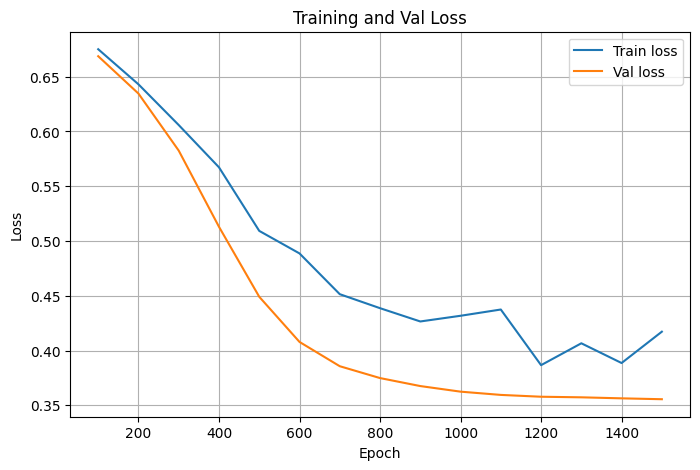

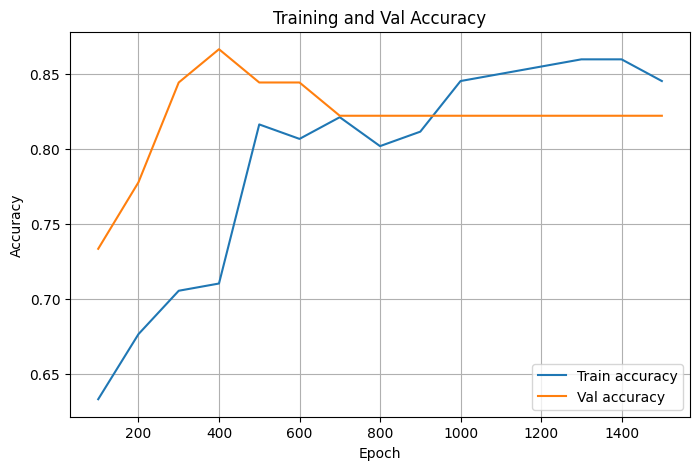

In [30]:
import matplotlib.pyplot as plt

epochs = range(100, EPOCHS + 1, 100)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Val Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graphe 2 : Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, val_accuracies, label="Val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Val Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
mlp_model.eval()

with torch.no_grad() :

    yt_pred = mlp_model(Xt_test)

    test_loss = criterion(yt_pred, yt_test).item()

    yt_pred_class = torch.argmax(yt_pred, dim=1)
    test_acc = accuracy(yt_pred_class, yt_test).item()

print(f"Test loss: {test_loss:.4f}; Test accuracy: {test_acc:.2%}")

Test loss: 0.3707; Test accuracy: 84.44%


In [32]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(
    yt_test.cpu().numpy(),
    yt_pred_class.cpu().numpy()
))

print(classification_report(
    yt_test.cpu().numpy(),
    yt_pred_class.cpu().numpy(),
    zero_division=0
))

[[23  1]
 [ 6 15]]
              precision    recall  f1-score   support

           0       0.79      0.96      0.87        24
           1       0.94      0.71      0.81        21

    accuracy                           0.84        45
   macro avg       0.87      0.84      0.84        45
weighted avg       0.86      0.84      0.84        45



Logistic Regression

In [33]:
model_reg = sklearn.linear_model.LogisticRegressionCV(max_iter=1000, random_state=RANDOM_STATE)

model_reg.fit(X_train, y_train)

y_pred = model_reg.predict(X_test)
y_proba = model_reg.predict_proba(X_test)

loss = sklearn.metrics.log_loss(y_test, y_proba)
acc = sklearn.metrics.accuracy_score(y_test, y_pred)

print(f"Loss: {loss:.4f}")
print(f"Accuracy: {acc:.2%}")

c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2137: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set 

Loss: 0.4783
Accuracy: 84.44%


Random Forest

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

model = RandomForestClassifier(random_state=42)

params = {
    "n_estimators": [10, 25, 50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 3, 5]
}

grid = GridSearchCV(
    model,
    params,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)

loss = sklearn.metrics.log_loss(y_test, y_proba)
acc = sklearn.metrics.accuracy_score(y_test, y_pred)

print(f"Loss: {loss:.4f}")
print(f"Accuracy: {acc:.2%}")

{'max_depth': None, 'min_samples_split': 3, 'n_estimators': 200}
0.8499419279907083

Loss: 0.3814
Accuracy: 84.44%
